In [3]:
import pandas as pd
import numpy as np

print("E-Commerce Intelligence System")
print("Notebook is ready!")
print("Let's build something BIG!")

E-Commerce Intelligence System
Notebook is ready!
Let's build something BIG!


In [4]:

# Load the Orders Dataset

orders = pd.read_csv("../data/raw/olist_orders_dataset.csv")

# Display the first 5 rows
orders.head()


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [3]:
# Check the dataset size
print("Dataset Shape:", orders.shape)

# Check all column names
print("\nColumns:")
print(orders.columns.tolist())

# Check missing values
print("\nMissing Values:")
print(orders.isnull().sum())

Dataset Shape: (99441, 8)

Columns:
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']

Missing Values:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64


In [5]:
orders["order_status"].value_counts()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

In [6]:
status_percentage = (
    orders["order_status"].value_counts(normalize=True) * 100
)

print(status_percentage.round(2))

order_status
delivered      97.02
shipped         1.11
canceled        0.63
unavailable     0.61
invoiced        0.32
processing      0.30
created         0.01
approved        0.00
Name: proportion, dtype: float64


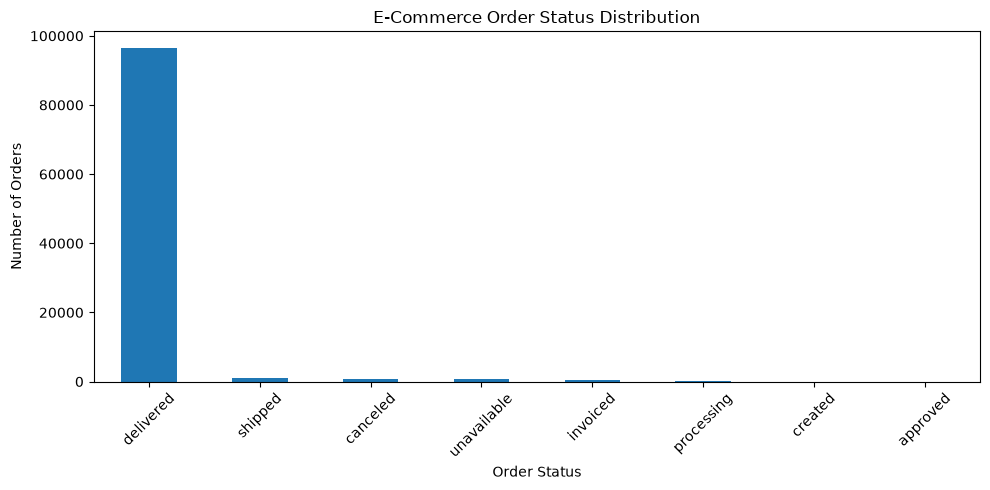

In [7]:
import matplotlib.pyplot as plt

status_counts = orders["order_status"].value_counts()

plt.figure(figsize=(10, 5))
status_counts.plot(kind="bar")

plt.title("E-Commerce Order Status Distribution")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [8]:

# Convert order dates into datetime format

orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"]
)

# Check the data type
print("Data type:", orders["order_purchase_timestamp"].dtype)

# Display first 5 dates
orders["order_purchase_timestamp"].head()


Data type: datetime64[us]


0   2017-10-02 10:56:33
1   2018-07-24 20:41:37
2   2018-08-08 08:38:49
3   2017-11-18 19:28:06
4   2018-02-13 21:18:39
Name: order_purchase_timestamp, dtype: datetime64[us]

In [9]:
# Extract year and month from purchase date

orders["order_year"] = orders["order_purchase_timestamp"].dt.year
orders["order_month"] = orders["order_purchase_timestamp"].dt.month

# Display the first 5 rows
orders[["order_purchase_timestamp", "order_year", "order_month"]].head()

,order_purchase_timestamp,order_year,order_month
0,2017-10-02 10:56:33,2017,10
1,2018-07-24 20:41:37,2018,7
2,2018-08-08 08:38:49,2018,8
3,2017-11-18 19:28:06,2017,11
4,2018-02-13 21:18:39,2018,2


In [10]:
# Count orders by year and month

monthly_orders = orders.groupby(
    ["order_year", "order_month"]
).size().reset_index(name="total_orders")

print(monthly_orders)

    order_year  order_month  total_orders
0         2016            9             4
1         2016           10           324
2         2016           12             1
3         2017            1           800
4         2017            2          1780
5         2017            3          2682
6         2017            4          2404
7         2017            5          3700
8         2017            6          3245
9         2017            7          4026
10        2017            8          4331
11        2017            9          4285
12        2017           10          4631
13        2017           11          7544
14        2017           12          5673
15        2018            1          7269
16        2018            2          6728
17        2018            3          7211
18        2018            4          6939
19        2018            5          6873
20        2018            6          6167
21        2018            7          6292
22        2018            8       

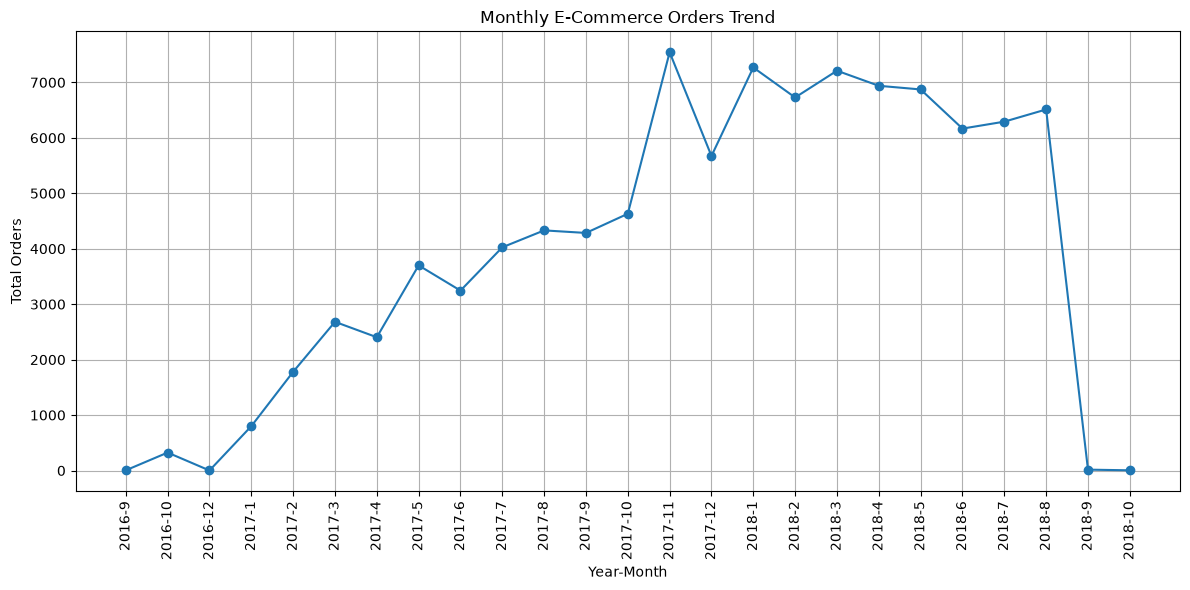

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_orders["order_year"].astype(str) + "-" +
    monthly_orders["order_month"].astype(str),
    monthly_orders["total_orders"],
    marker="o"
)

plt.title("Monthly E-Commerce Orders Trend")
plt.xlabel("Year-Month")
plt.ylabel("Total Orders")
plt.xticks(rotation=90)
plt.grid(True)
plt.tight_layout()

plt.show()

In [12]:
# Select only successfully delivered orders

delivered_orders = orders[
    orders["order_status"] == "delivered"
].copy()

# Convert delivery date into datetime format

delivered_orders["order_delivered_customer_date"] = pd.to_datetime(
    delivered_orders["order_delivered_customer_date"]
)

# Calculate delivery time in days

delivered_orders["delivery_time_days"] = (
    delivered_orders["order_delivered_customer_date"] -
    delivered_orders["order_purchase_timestamp"]
).dt.total_seconds() / 86400

# Display first 5 results

delivered_orders[
    ["order_purchase_timestamp",
     "order_delivered_customer_date",
     "delivery_time_days"]
].head()

,order_purchase_timestamp,order_delivered_customer_date,delivery_time_days
0,2017-10-02 10:56:33,2017-10-10 21:25:13,8.436574
1,2018-07-24 20:41:37,2018-08-07 15:27:45,13.782037
2,2018-08-08 08:38:49,2018-08-17 18:06:29,9.394213
3,2017-11-18 19:28:06,2017-12-02 00:28:42,13.208750
4,2018-02-13 21:18:39,2018-02-16 18:17:02,2.873877


In [13]:
average_delivery = delivered_orders["delivery_time_days"].mean()

print("Average Delivery Time:", round(average_delivery, 2), "days")

Average Delivery Time: 12.56 days


In [14]:
# Convert estimated delivery date

delivered_orders["order_estimated_delivery_date"] = pd.to_datetime(
    delivered_orders["order_estimated_delivery_date"]
)

# Calculate delivery difference

delivered_orders["delivery_difference"] = (
    delivered_orders["order_delivered_customer_date"] -
    delivered_orders["order_estimated_delivery_date"]
).dt.total_seconds() / 86400

# Count early and late deliveries

early_deliveries = (delivered_orders["delivery_difference"] < 0).sum()
late_deliveries = (delivered_orders["delivery_difference"] > 0).sum()
on_time_deliveries = (delivered_orders["delivery_difference"] == 0).sum()

print("Early Deliveries:", early_deliveries)
print("Late Deliveries:", late_deliveries)
print("Exactly on Estimated Date:", on_time_deliveries)

Early Deliveries: 88644
Late Deliveries: 7826
Exactly on Estimated Date: 0


In [15]:
total_delivered = len(delivered_orders)

late_percentage = (
    late_deliveries / total_delivered
) * 100

early_percentage = (
    early_deliveries / total_delivered
) * 100

print("Early Delivery Percentage:", round(early_percentage, 2), "%")
print("Late Delivery Percentage:", round(late_percentage, 2), "%")

Early Delivery Percentage: 91.88 %
Late Delivery Percentage: 8.11 %


In [16]:
print("Total delivered orders:", len(delivered_orders))
print("Missing delivery comparisons:", delivered_orders["delivery_difference"].isna().sum())

Total delivered orders: 96478
Missing delivery comparisons: 8


In [17]:
valid_delivery_comparisons = delivered_orders["delivery_difference"].notna().sum()

early_percentage = (
    early_deliveries / valid_delivery_comparisons
) * 100

late_percentage = (
    late_deliveries / valid_delivery_comparisons
) * 100

print("Valid Delivery Comparisons:", valid_delivery_comparisons)
print("Early Delivery Percentage:", round(early_percentage, 2), "%")
print("Late Delivery Percentage:", round(late_percentage, 2), "%")

Valid Delivery Comparisons: 96470
Early Delivery Percentage: 91.89 %
Late Delivery Percentage: 8.11 %


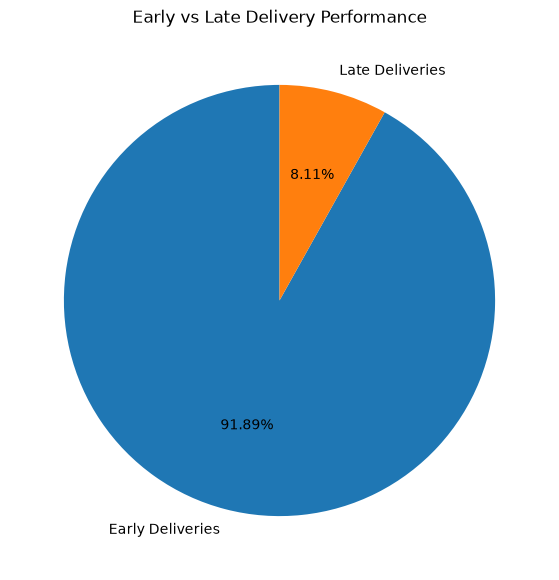

In [18]:
delivery_counts = [
    early_deliveries,
    late_deliveries
]

plt.figure(figsize=(7, 7))

plt.pie(
    delivery_counts,
    labels=["Early Deliveries", "Late Deliveries"],
    autopct="%1.2f%%",
    startangle=90
)

plt.title("Early vs Late Delivery Performance")
plt.show()


### Delivery Performance Insights

1. 91.89% of orders were delivered earlier than the estimated date.
2. 8.11% of orders were delivered later than the estimated date.
3. The average delivery time was 12.56 days.
4. Overall, the dataset shows strong delivery performance.

**Conclusion:** Most orders in the dataset reached customers before their estimated delivery dates.


In [20]:
customers = pd.read_csv(
    "../data/raw/olist_customers_dataset.csv"
)

customers.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [21]:
print("Customer Dataset Shape:", customers.shape)

print("\nMissing Values:")
print(customers.isnull().sum())

Customer Dataset Shape: (99441, 5)

Missing Values:
customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64


In [22]:
state_customers = customers["customer_state"].value_counts()

print(state_customers)

customer_state
SP    41746
RJ    12852
MG    11635
RS     5466
PR     5045
SC     3637
BA     3380
DF     2140
ES     2033
GO     2020
PE     1652
CE     1336
PA      975
MT      907
MA      747
MS      715
PB      536
PI      495
RN      485
AL      413
SE      350
TO      280
RO      253
AM      148
AC       81
AP       68
RR       46
Name: count, dtype: int64


In [23]:
top_10_states = state_customers.head(10)

print(top_10_states)

customer_state
SP    41746
RJ    12852
MG    11635
RS     5466
PR     5045
SC     3637
BA     3380
DF     2140
ES     2033
GO     2020
Name: count, dtype: int64


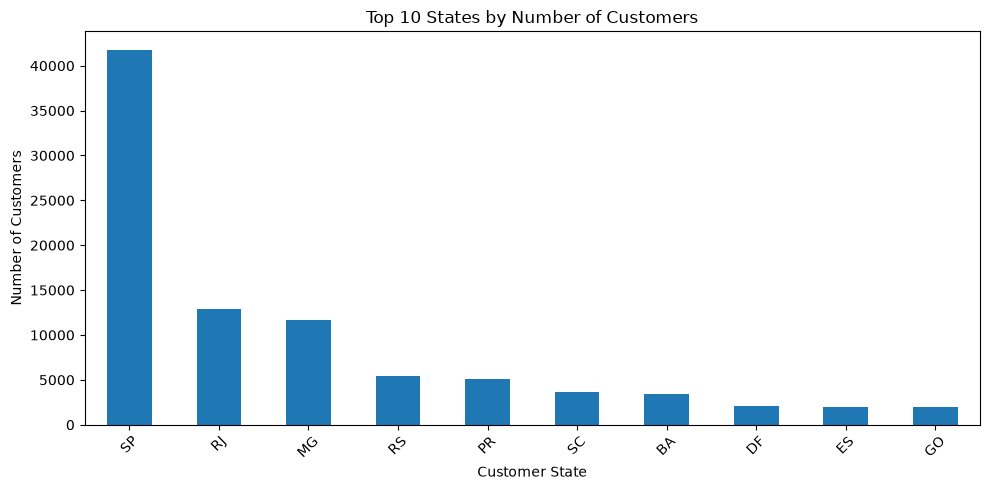

In [24]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

top_10_states.plot(kind="bar")

plt.title("Top 10 States by Number of Customers")
plt.xlabel("Customer State")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### Customer Distribution Insights

1. São Paulo (SP) has the highest number of customers with 41,746.
2. Rio de Janeiro (RJ) ranks second with 12,852 customers.
3. Minas Gerais (MG) ranks third with 11,635 customers.
4. Most customers are concentrated in the top three states.

**Conclusion:** São Paulo is the largest customer market in the dataset.

In [26]:
city_customers = customers["customer_city"].value_counts()

top_10_cities = city_customers.head(10)

print(top_10_cities)

customer_city
sao paulo                15540
rio de janeiro            6882
belo horizonte            2773
brasilia                  2131
curitiba                  1521
campinas                  1444
porto alegre              1379
salvador                  1245
guarulhos                 1189
sao bernardo do campo      938
Name: count, dtype: int64


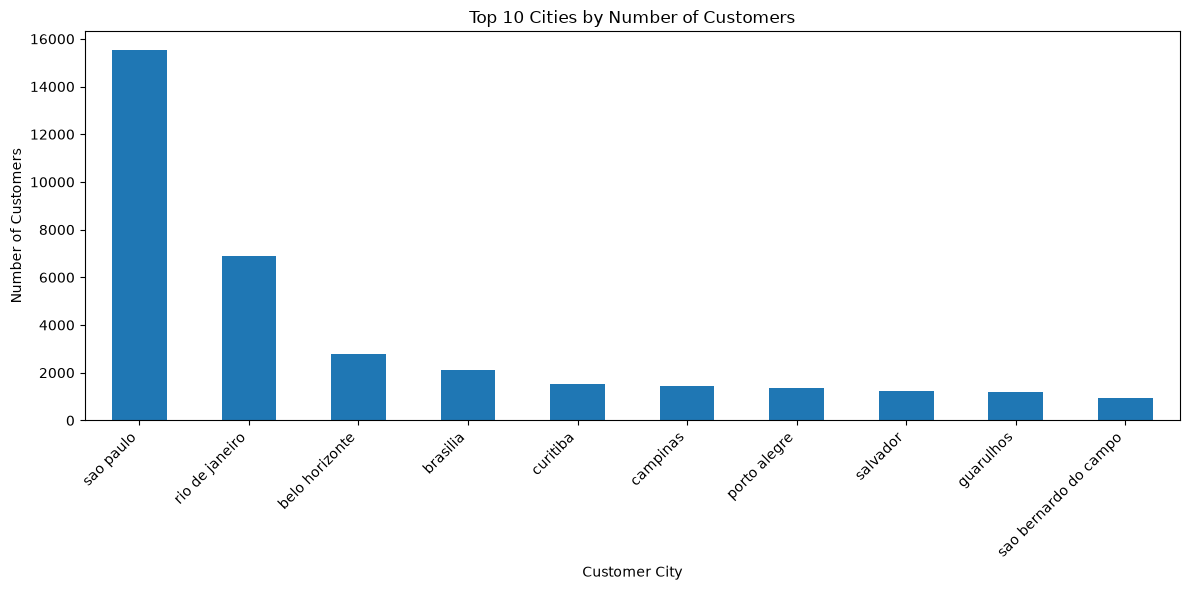

In [27]:
plt.figure(figsize=(12, 6))

top_10_cities.plot(kind="bar")

plt.title("Top 10 Cities by Number of Customers")
plt.xlabel("Customer City")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

### Customer City Analysis Insights

1. São Paulo has the highest number of customers with 15,540.
2. Rio de Janeiro ranks second with 6,882 customers.
3. Belo Horizonte ranks third with 2,773 customers.
4. Most customers are concentrated in a few major cities.
5. São Paulo is the leading customer city in the dataset.

**Conclusion:** São Paulo has the largest customer base among the cities analysed.

In [28]:
order_items = pd.read_csv(
    "../data/raw/olist_order_items_dataset.csv"
)

order_items.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [29]:
print("Order Items Dataset Shape:", order_items.shape)

print("\nMissing Values:")
print(order_items.isnull().sum())

Order Items Dataset Shape: (112650, 7)

Missing Values:
order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64


In [30]:
total_revenue = order_items["price"].sum()

print("Total Revenue: R$", round(total_revenue, 2))

Total Revenue: R$ 13591643.7


In [31]:
total_orders = order_items["order_id"].nunique()

average_order_value = total_revenue / total_orders

print("Total Unique Orders:", total_orders)
print("Average Order Value: R$", round(average_order_value, 2))

Total Unique Orders: 98666
Average Order Value: R$ 137.75


In [32]:
top_products = order_items["product_id"].value_counts().head(10)

print(top_products)

product_id
aca2eb7d00ea1a7b8ebd4e68314663af    527
99a4788cb24856965c36a24e339b6058    488
422879e10f46682990de24d770e7f83d    484
389d119b48cf3043d311335e499d9c6b    392
368c6c730842d78016ad823897a372db    388
53759a2ecddad2bb87a079a1f1519f73    373
d1c427060a0f73f6b889a5c7c61f2ac4    343
53b36df67ebb7c41585e8d54d6772e08    323
154e7e31ebfa092203795c972e5804a6    281
3dd2a17168ec895c781a9191c1e95ad7    274
Name: count, dtype: int64


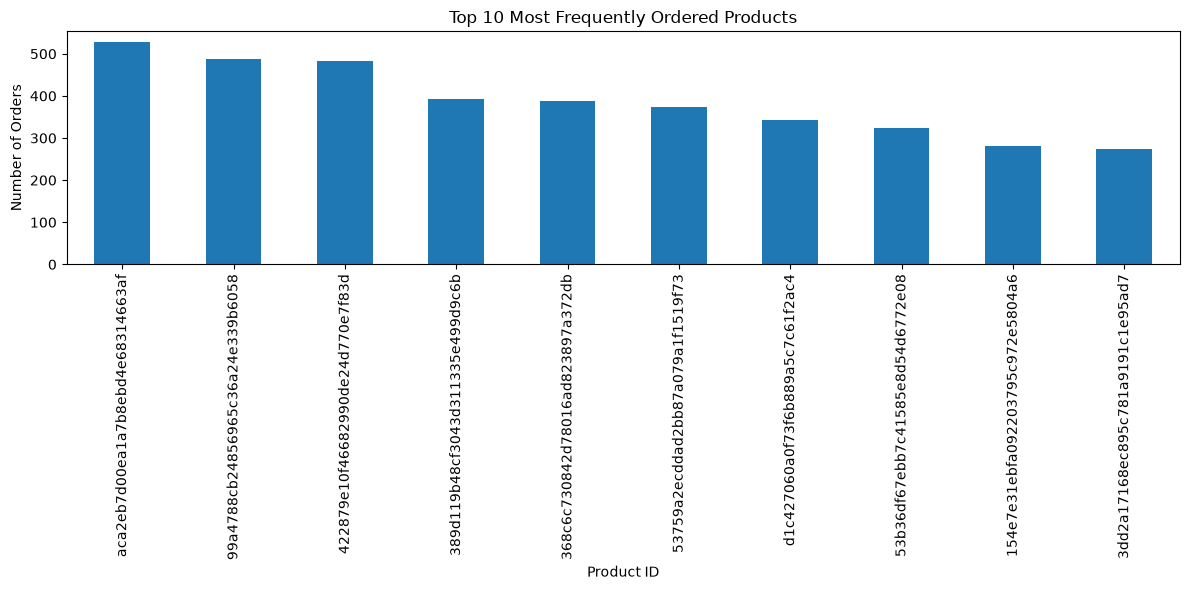

In [33]:
plt.figure(figsize=(12, 6))

top_products.plot(kind="bar")

plt.title("Top 10 Most Frequently Ordered Products")
plt.xlabel("Product ID")
plt.ylabel("Number of Orders")
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

In [34]:
products = pd.read_csv(
    "../data/raw/olist_products_dataset.csv"
)

products.head()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


In [35]:
print("Products Dataset Shape:", products.shape)

print("\nMissing Values:")
print(products.isnull().sum())

Products Dataset Shape: (32951, 9)

Missing Values:
product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64


In [36]:
category_translation = pd.read_csv(
    "../data/raw/product_category_name_translation.csv"
)

category_translation.head()

,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor


In [37]:
products = products.merge(
    category_translation,
    on="product_category_name",
    how="left"
)

products[[
    "product_id",
    "product_category_name",
    "product_category_name_english"
]].head()

,product_id,product_category_name,product_category_name_english
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,perfumery
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,art
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,sports_leisure
3,cef67bcfe19066a932b7673e239eb23d,bebes,baby
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,housewares


In [38]:
sales_data = order_items.merge(
    products,
    on="product_id",
    how="left"
)

category_sales = (
    sales_data["product_category_name_english"]
    .value_counts()
    .head(10)
)

print(category_sales)

product_category_name_english
bed_bath_table           11115
health_beauty             9670
sports_leisure            8641
furniture_decor           8334
computers_accessories     7827
housewares                6964
watches_gifts             5991
telephony                 4545
garden_tools              4347
auto                      4235
Name: count, dtype: int64


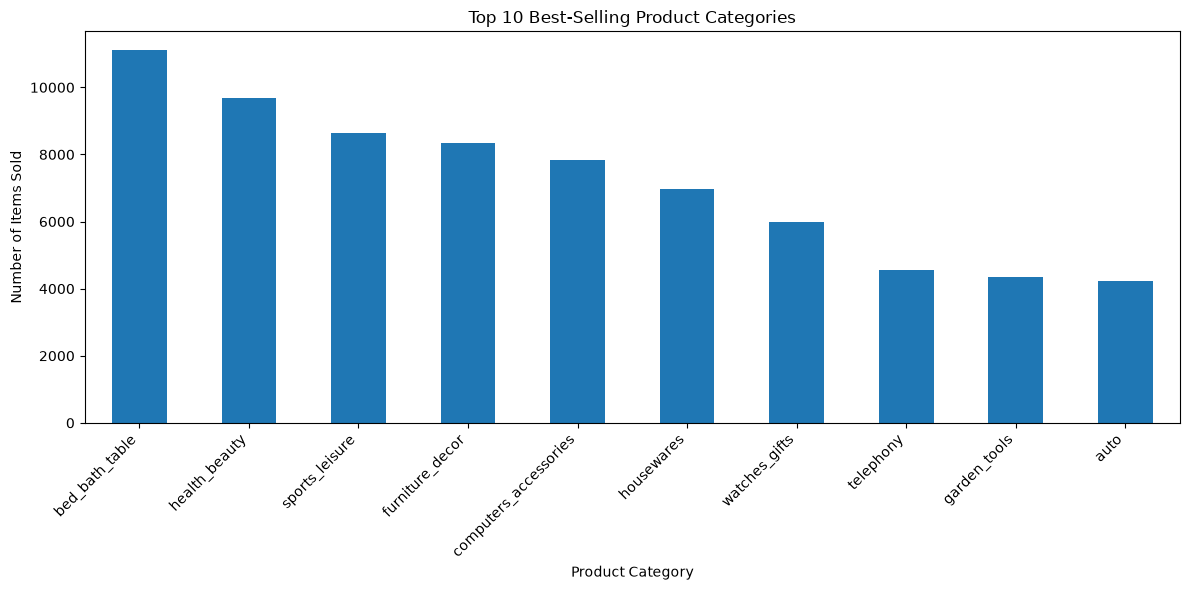

In [39]:
plt.figure(figsize=(12, 6))

category_sales.plot(kind="bar")

plt.title("Top 10 Best-Selling Product Categories")
plt.xlabel("Product Category")
plt.ylabel("Number of Items Sold")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [40]:
print(category_sales)

product_category_name_english
bed_bath_table           11115
health_beauty             9670
sports_leisure            8641
furniture_decor           8334
computers_accessories     7827
housewares                6964
watches_gifts             5991
telephony                 4545
garden_tools              4347
auto                      4235
Name: count, dtype: int64


### Product Category Sales Insights

1. Bed, Bath and Table is the best-selling category with 11,115 items sold.
2. Health and Beauty ranks second with 9,670 items sold.
3. Sports and Leisure ranks third with 8,641 items sold.
4. Furniture Decor and Computers Accessories also have high sales.
5. Auto is the tenth category with 4,235 items sold.

**Conclusion:** Bed, Bath and Table is the most popular product category, while home-related and lifestyle products show strong demand.

In [41]:
payments = pd.read_csv("../data/raw/olist_order_payments_dataset.csv")

print("Payment Dataset Shape:", payments.shape)

print("\nPayment Methods:")
print(payments["payment_type"].value_counts())

Payment Dataset Shape: (103886, 5)

Payment Methods:
payment_type
credit_card    76795
boleto         19784
voucher         5775
debit_card      1529
not_defined        3
Name: count, dtype: int64


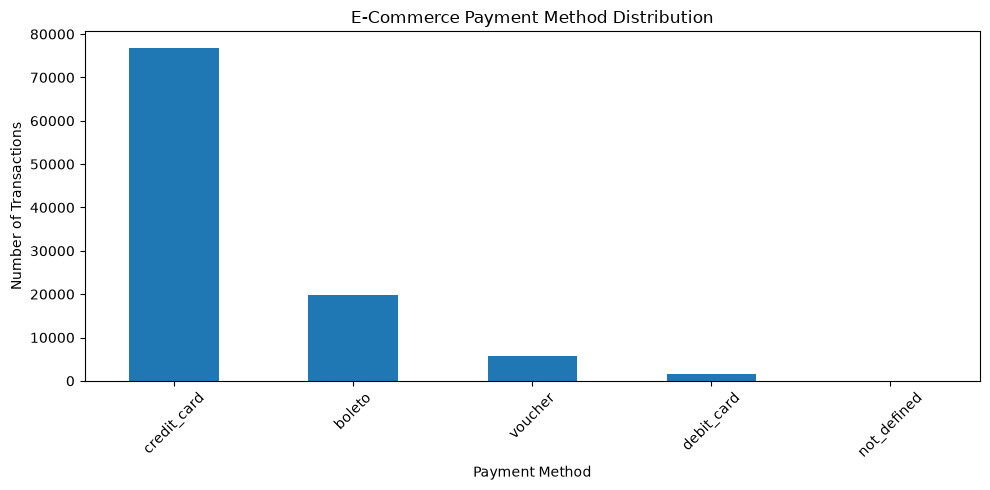

In [42]:
plt.figure(figsize=(10, 5))

payments["payment_type"].value_counts().plot(kind="bar")

plt.title("E-Commerce Payment Method Distribution")
plt.xlabel("Payment Method")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### Payment Method Analysis Insights

1. Credit Card is the most popular payment method with 76,795 transactions.
2. Boleto ranks second with 19,784 transactions.
3. Vouchers account for 5,775 transactions.
4. Debit Cards account for 1,529 transactions.
5. Only 3 transactions have an undefined payment method.

**Conclusion:** Credit Cards are the most widely used payment method among customers, showing a strong preference for card-based payments.

In [43]:
payment_analysis = payments.groupby("payment_type")["payment_value"].agg(
    ["count", "sum", "mean"]
)

payment_analysis = payment_analysis.round(2)

print(payment_analysis)

              count          sum    mean
payment_type                            
boleto        19784   2869361.27  145.03
credit_card   76795  12542084.19  163.32
debit_card     1529    217989.79  142.57
not_defined       3         0.00    0.00
voucher        5775    379436.87   65.70


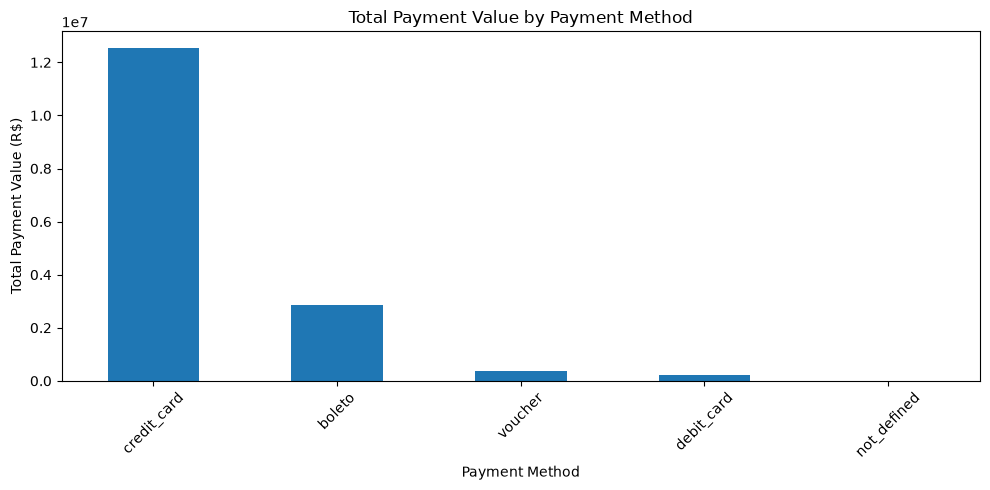

In [44]:
plt.figure(figsize=(10, 5))

payment_analysis["sum"].sort_values(ascending=False).plot(kind="bar")

plt.title("Total Payment Value by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Total Payment Value (R$)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### Payment Value Analysis Insights

1. Credit Cards contribute the highest total payment value.
2. Boleto is the second-highest payment method.
3. Vouchers contribute less than Credit Cards and Boleto.
4. Debit Cards contribute a smaller share of total payments.
5. Undefined payment methods contribute the least.

**Conclusion:** Credit Cards are the leading payment method in terms of both transaction count and total payment value.

In [45]:
print("Payment Installments Distribution:")
print(payments["payment_installments"].value_counts().sort_index())

Payment Installments Distribution:
payment_installments
0         2
1     52546
2     12413
3     10461
4      7098
5      5239
6      3920
7      1626
8      4268
9       644
10     5328
11       23
12      133
13       16
14       15
15       74
16        5
17        8
18       27
20       17
21        3
22        1
23        1
24       18
Name: count, dtype: int64


### Payment Installment Analysis Insights

1. Most customers paid in a single installment (52,546 transactions).
2. Two installments were used in 12,413 transactions.
3. Three installments were used in 10,461 transactions.
4. A smaller number of customers selected longer installment plans.
5. Only 2 transactions have zero installments.

**Conclusion:** Most customers prefer paying for their purchases in a single installment rather than splitting payments.

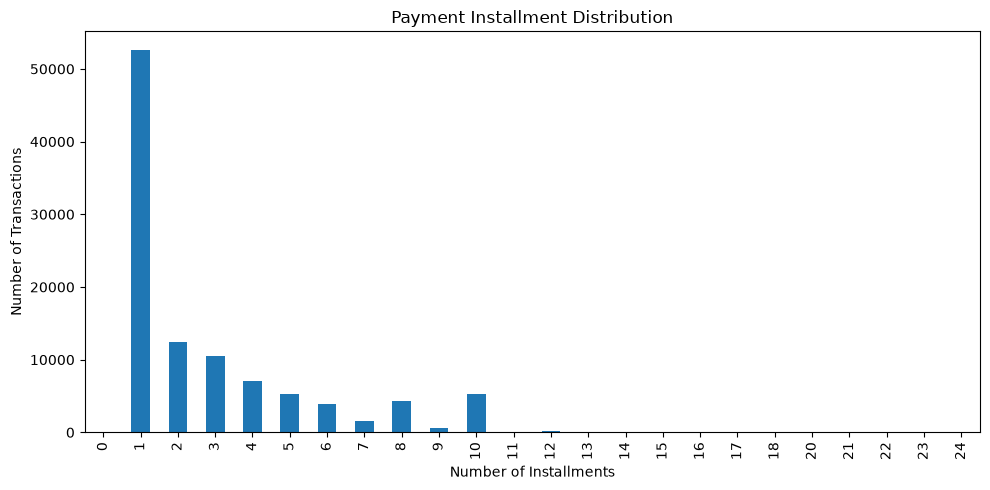

In [46]:
plt.figure(figsize=(10, 5))

payments["payment_installments"].value_counts().sort_index().plot(kind="bar")

plt.title("Payment Installment Distribution")
plt.xlabel("Number of Installments")
plt.ylabel("Number of Transactions")

plt.tight_layout()
plt.show()

### Payment Installment Distribution Insights

1. 52,546 transactions were made using a single installment.
2. 12,413 transactions used two installments.
3. 10,461 transactions used three installments.
4. Very few customers selected more than 10 installments.
5. Only 2 transactions had zero installments.

**Conclusion:** Most customers prefer paying in a single installment.

In [47]:
reviews = pd.read_csv("../data/raw/olist_order_reviews_dataset.csv")

print("Review Dataset Shape:", reviews.shape)

print("\nMissing Values:")
print(reviews.isnull().sum())

Review Dataset Shape: (99224, 7)

Missing Values:
review_id                      0
order_id                       0
review_score                   0
review_comment_title       87656
review_comment_message     58247
review_creation_date           0
review_answer_timestamp        0
dtype: int64


In [48]:
print("Review Score Distribution:")
print(reviews["review_score"].value_counts().sort_index())

Review Score Distribution:
review_score
1    11424
2     3151
3     8179
4    19142
5    57328
Name: count, dtype: int64


In [49]:
print("Review Score Distribution:")
print(reviews["review_score"].value_counts().sort_index())

Review Score Distribution:
review_score
1    11424
2     3151
3     8179
4    19142
5    57328
Name: count, dtype: int64


### Customer Review Analysis Insights

1. 57,328 customers gave a 5-star rating.
2. 19,142 customers gave a 4-star rating.
3. 8,179 customers gave a 3-star rating.
4. 3,151 customers gave a 2-star rating.
5. 11,424 customers gave a 1-star rating.

**Conclusion:** Most customers gave positive ratings, with 5 stars being the most common review score.

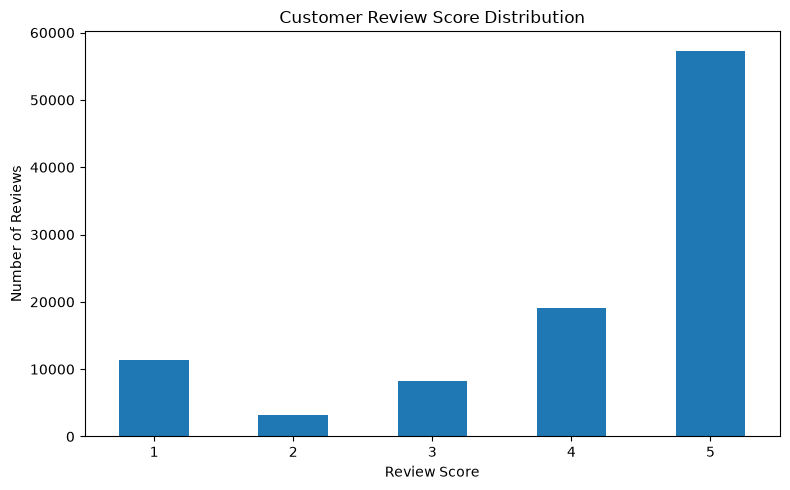

In [50]:
plt.figure(figsize=(8, 5))

reviews["review_score"].value_counts().sort_index().plot(kind="bar")

plt.title("Customer Review Score Distribution")
plt.xlabel("Review Score")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [51]:
average_rating = reviews["review_score"].mean()

print("Average Customer Rating:", round(average_rating, 2), "/ 5")

Average Customer Rating: 4.09 / 5


### Average Customer Rating Insights

1. The average customer review rating is 4.09 out of 5.
2. Most customers gave 5-star ratings.
3. The average rating indicates generally positive customer satisfaction.
4. Only a smaller number of customers gave 1-star or 2-star ratings.

**Conclusion:** Customers are generally satisfied with their shopping experience.

In [52]:
review_percentages = (
    reviews["review_score"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

print(review_percentages.round(2))

review_score
1    11.51
2     3.18
3     8.24
4    19.29
5    57.78
Name: proportion, dtype: float64


### Customer Review Percentage Insights

1. 57.78% of customers gave 5-star ratings.
2. 19.29% gave 4-star ratings.
3. 8.24% gave 3-star ratings.
4. 3.18% gave 2-star ratings.
5. 11.51% gave 1-star ratings.

**Conclusion:** More than half of the customers gave 5-star ratings, indicating generally positive customer satisfaction.

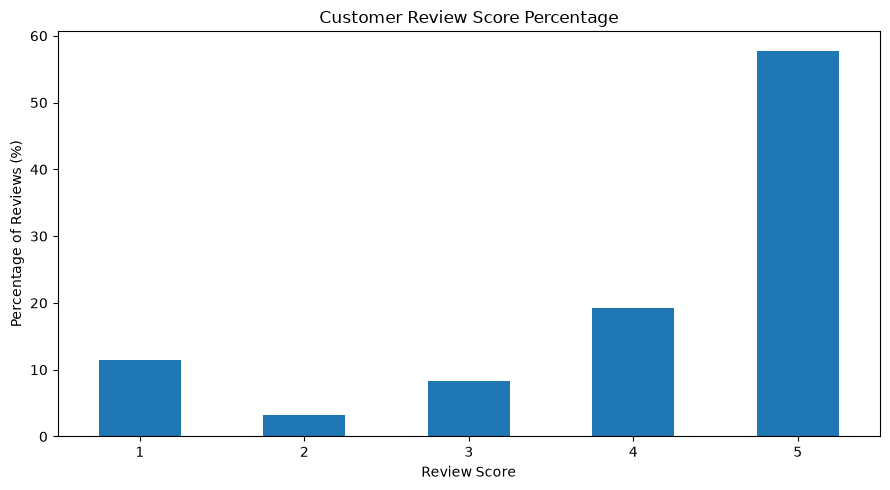

In [54]:
plt.figure(figsize=(9, 5))

review_percentages.plot(kind="bar")

plt.title("Customer Review Score Percentage")
plt.xlabel("Review Score")
plt.ylabel("Percentage of Reviews (%)")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [55]:
print("Review Comment Titles:")
print(reviews["review_comment_title"].dropna().head(10))

print("\nReview Messages:")
print(reviews["review_comment_message"].dropna().head(10))

Review Comment Titles:
9                   recomendo
15            Super recomendo
19    Não chegou meu produto 
22                      Ótimo
34                 Muito bom.
36                        Bom
38               Maravilhoso!
43           Entrega perfeita
53                      Ótimo
59                   MT lindo
Name: review_comment_title, dtype: str

Review Messages:
3                 Recebi bem antes do prazo estipulado.
4     Parabéns lojas lannister adorei comprar pela I...
9     aparelho eficiente. no site a marca do aparelh...
12      Mas um pouco ,travando...pelo valor ta Boa.\r\n
15    Vendedor confiável, produto ok e entrega antes...
16    GOSTARIA DE SABER O QUE HOUVE, SEMPRE RECEBI E...
19                                              Péssimo
22                                         Loja nota 10
24                obrigado pela atençao amim dispensada
27    A compra foi realizada facilmente.\r\nA entreg...
Name: review_comment_message, dtype: str


In [56]:
reviews_with_comments = reviews["review_comment_message"].notna().sum()
reviews_without_comments = reviews["review_comment_message"].isna().sum()

print("Reviews with Comments:", reviews_with_comments)
print("Reviews without Comments:", reviews_without_comments)

Reviews with Comments: 40977
Reviews without Comments: 58247


### Customer Review Comment Insights

1. 40,977 customers submitted written review comments.
2. 58,247 customers did not write any comments.
3. Most customers submitted ratings without writing detailed feedback.
4. Written comments provide additional information about customer experiences.

**Conclusion:** Although many customers did not write comments, the available feedback can help understand customer satisfaction.

In [57]:
total_reviews = len(reviews)

comment_percentage = (reviews_with_comments / total_reviews) * 100
no_comment_percentage = (reviews_without_comments / total_reviews) * 100

print("Reviews with Comments:", round(comment_percentage, 2), "%")
print("Reviews without Comments:", round(no_comment_percentage, 2), "%")

Reviews with Comments: 41.3 %
Reviews without Comments: 58.7 %


### Customer Comment Percentage Insights

1. 41.3% of customers submitted written comments.
2. 58.7% of customers did not submit written comments.
3. More customers provided ratings without writing additional feedback.
4. Written comments can help identify customer experiences and complaints.

**Conclusion:** Most customers rated their purchases without providing written comments.

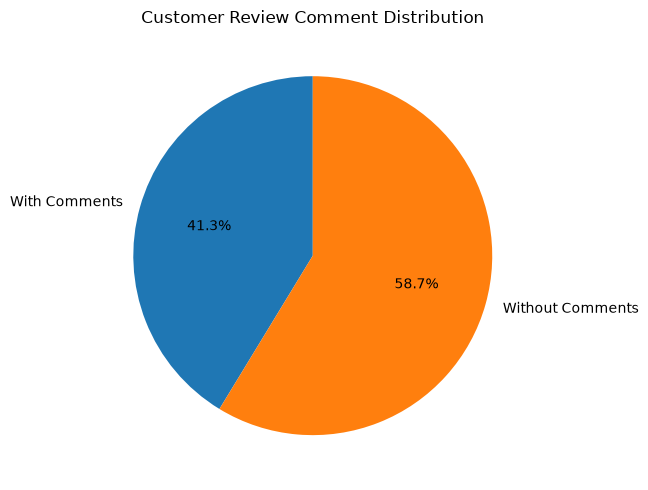

In [58]:
comment_data = pd.Series({
    "With Comments": reviews_with_comments,
    "Without Comments": reviews_without_comments
})

plt.figure(figsize=(7, 5))

comment_data.plot(kind="pie", autopct="%1.1f%%", startangle=90)

plt.title("Customer Review Comment Distribution")
plt.ylabel("")

plt.tight_layout()
plt.show()

In [59]:
print("TOTAL REVIEWS:", len(reviews))
print("AVERAGE RATING:", round(reviews["review_score"].mean(), 2))
print("5-STAR REVIEWS:", (reviews["review_score"] == 5).sum())
print("1-STAR REVIEWS:", (reviews["review_score"] == 1).sum())
print("REVIEWS WITH COMMENTS:", reviews_with_comments)
print("REVIEWS WITHOUT COMMENTS:", reviews_without_comments)

TOTAL REVIEWS: 99224
AVERAGE RATING: 4.09
5-STAR REVIEWS: 57328
1-STAR REVIEWS: 11424
REVIEWS WITH COMMENTS: 40977
REVIEWS WITHOUT COMMENTS: 58247


In [60]:
print("Orders Duplicates:", orders.duplicated().sum())
print("Customers Duplicates:", customers.duplicated().sum())
print("Products Duplicates:", products.duplicated().sum())
print("Order Items Duplicates:", order_items.duplicated().sum())
print("Payments Duplicates:", payments.duplicated().sum())
print("Reviews Duplicates:", reviews.duplicated().sum())

Orders Duplicates: 0
Customers Duplicates: 0
Products Duplicates: 0
Order Items Duplicates: 0
Payments Duplicates: 0
Reviews Duplicates: 0


In [61]:
datasets = {
    "Orders": orders,
    "Customers": customers,
    "Products": products,
    "Order Items": order_items,
    "Payments": payments,
    "Reviews": reviews
}

for name, df in datasets.items():
    print(f"\n{name}")
    print("Total Missing Values:", df.isnull().sum().sum())


Orders
Total Missing Values: 4908

Customers
Total Missing Values: 0

Products
Total Missing Values: 3071

Order Items
Total Missing Values: 0

Payments
Total Missing Values: 0

Reviews
Total Missing Values: 145903


In [62]:
for name, df in datasets.items():
    missing = df.isnull().sum()
    missing = missing[missing > 0]

    if not missing.empty:
        print(f"\n--- {name} ---")
        print(missing)


--- Orders ---
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
dtype: int64

--- Products ---
product_category_name            610
product_name_lenght              610
product_description_lenght       610
product_photos_qty               610
product_weight_g                   2
product_length_cm                  2
product_height_cm                  2
product_width_cm                   2
product_category_name_english    623
dtype: int64

--- Reviews ---
review_comment_title      87656
review_comment_message    58247
dtype: int64


In [63]:
missing_delivery = orders[
    orders["order_delivered_customer_date"].isnull()
]

print("Missing Delivery Dates by Order Status:")
print(missing_delivery["order_status"].value_counts())

Missing Delivery Dates by Order Status:
order_status
shipped        1107
canceled        619
unavailable     609
invoiced        314
processing      301
delivered         8
created           5
approved          2
Name: count, dtype: int64


In [64]:
missing_delivered = orders[
    (orders["order_status"] == "delivered") &
    (orders["order_delivered_customer_date"].isnull())
]

print(missing_delivered)

                               order_id                       customer_id  \
3002   2d1e2d5bf4dc7227b3bfebb81328c15f  ec05a6d8558c6455f0cbbd8a420ad34f   
20618  f5dd62b788049ad9fc0526e3ad11a097  5e89028e024b381dc84a13a3570decb4   
43834  2ebdfc4f15f23b91474edf87475f108e  29f0540231702fda0cfdee0a310f11aa   
79263  e69f75a717d64fc5ecdfae42b2e8e086  cfda40ca8dd0a5d486a9635b611b398a   
82868  0d3268bad9b086af767785e3f0fc0133  4f1d63d35fb7c8999853b2699f5c7649   
92643  2d858f451373b04fb5c984a1cc2defaf  e08caf668d499a6d643dafd7c5cc498a   
97647  ab7c89dc1bf4a1ead9d6ec1ec8968a84  dd1b84a7286eb4524d52af4256c0ba24   
98038  20edc82cf5400ce95e1afacc25798b31  28c37425f1127d887d7337f284080a0f   

      order_status order_purchase_timestamp    order_approved_at  \
3002     delivered      2017-11-28 17:44:07  2017-11-28 17:56:40   
20618    delivered      2018-06-20 06:58:43  2018-06-20 07:19:05   
43834    delivered      2018-07-01 17:05:11  2018-07-01 17:15:12   
79263    delivered      2018-07-01

In [65]:
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 20)

print(
    missing_delivered[
        [
            "order_id",
            "order_status",
            "order_purchase_timestamp",
            "order_delivered_carrier_date",
            "order_delivered_customer_date"
        ]
    ].to_string(index=False)
)

                        order_id order_status order_purchase_timestamp order_delivered_carrier_date order_delivered_customer_date
2d1e2d5bf4dc7227b3bfebb81328c15f    delivered      2017-11-28 17:44:07          2017-11-30 18:12:23                           NaN
f5dd62b788049ad9fc0526e3ad11a097    delivered      2018-06-20 06:58:43          2018-06-25 08:05:00                           NaN
2ebdfc4f15f23b91474edf87475f108e    delivered      2018-07-01 17:05:11          2018-07-03 13:57:00                           NaN
e69f75a717d64fc5ecdfae42b2e8e086    delivered      2018-07-01 22:05:55          2018-07-03 13:57:00                           NaN
0d3268bad9b086af767785e3f0fc0133    delivered      2018-07-01 21:14:02          2018-07-03 09:28:00                           NaN
2d858f451373b04fb5c984a1cc2defaf    delivered      2017-05-25 23:22:43                          NaN                           NaN
ab7c89dc1bf4a1ead9d6ec1ec8968a84    delivered      2018-06-08 12:09:39          2018-06-12

In [66]:
missing_approval = orders[
    orders["order_approved_at"].isnull()
]

print("Missing Approval Dates by Order Status:")
print(missing_approval["order_status"].value_counts())

Missing Approval Dates by Order Status:
order_status
canceled     141
delivered     14
created        5
Name: count, dtype: int64


In [67]:
missing_approved_delivered = orders[
    (orders["order_status"] == "delivered") &
    (orders["order_approved_at"].isnull())
]

print(
    missing_approved_delivered[
        [
            "order_id",
            "order_purchase_timestamp",
            "order_approved_at",
            "order_delivered_carrier_date",
            "order_delivered_customer_date"
        ]
    ].to_string(index=False)
)

                        order_id order_purchase_timestamp order_approved_at order_delivered_carrier_date order_delivered_customer_date
e04abd8149ef81b95221e88f6ed9ab6a      2017-02-18 14:40:00               NaN          2017-02-23 12:04:47           2017-03-01 13:25:33
8a9adc69528e1001fc68dd0aaebbb54a      2017-02-18 12:45:31               NaN          2017-02-23 09:01:52           2017-03-02 10:05:06
7013bcfc1c97fe719a7b5e05e61c12db      2017-02-18 13:29:47               NaN          2017-02-22 16:25:25           2017-03-01 08:07:38
5cf925b116421afa85ee25e99b4c34fb      2017-02-18 16:48:35               NaN          2017-02-22 11:23:10           2017-03-09 07:28:47
12a95a3c06dbaec84bcfb0e2da5d228a      2017-02-17 13:05:55               NaN          2017-02-22 11:23:11           2017-03-02 11:09:19
c1d4211b3dae76144deccd6c74144a88      2017-01-19 12:48:08               NaN          2017-01-25 14:56:50           2017-01-30 18:16:01
d69e5d356402adc8cf17e08b5033acfb      2017-02-19 01:28:

In [68]:
orders_clean = orders.copy()

date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_columns:
    orders_clean[col] = pd.to_datetime(
        orders_clean[col],
        errors="coerce"
    )

print("Cleaned Orders Shape:", orders_clean.shape)
print("\nMissing Values After Cleaning:")
print(orders_clean.isnull().sum())

Cleaned Orders Shape: (99441, 10)

Missing Values After Cleaning:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
order_year                          0
order_month                         0
dtype: int64


In [69]:
products_clean = products.copy()

products_clean["product_category_name"] = (
    products_clean["product_category_name"].fillna("unknown")
)

products_clean["product_category_name_english"] = (
    products_clean["product_category_name_english"].fillna("unknown")
)

print("Cleaned Products Shape:", products_clean.shape)
print("\nMissing Values After Cleaning:")
print(products_clean.isnull().sum())

Cleaned Products Shape: (32951, 10)

Missing Values After Cleaning:
product_id                         0
product_category_name              0
product_name_lenght              610
product_description_lenght       610
product_photos_qty               610
product_weight_g                   2
product_length_cm                  2
product_height_cm                  2
product_width_cm                   2
product_category_name_english      0
dtype: int64


In [70]:
numeric_columns = [
    "product_name_lenght",
    "product_description_lenght",
    "product_photos_qty",
    "product_weight_g",
    "product_length_cm",
    "product_height_cm",
    "product_width_cm"
]

for col in numeric_columns:
    products_clean[col] = products_clean[col].fillna(
        products_clean[col].median()
    )

print("Missing Values After Final Cleaning:")
print(products_clean.isnull().sum().sum())

Missing Values After Final Cleaning:
0


In [71]:
reviews_clean = reviews.copy()

comment_columns = [
    "review_comment_title",
    "review_comment_message"
]

for col in comment_columns:
    reviews_clean[col] = reviews_clean[col].fillna("")

print("Cleaned Reviews Shape:", reviews_clean.shape)
print("\nMissing Values After Cleaning:")
print(reviews_clean.isnull().sum())

Cleaned Reviews Shape: (99224, 7)

Missing Values After Cleaning:
review_id                  0
order_id                   0
review_score               0
review_comment_title       0
review_comment_message     0
review_creation_date       0
review_answer_timestamp    0
dtype: int64


In [72]:
customers_clean = customers.copy()

print("Cleaned Customers Shape:", customers_clean.shape)
print("Missing Values:", customers_clean.isnull().sum().sum())
print("Duplicate Rows:", customers_clean.duplicated().sum())

Cleaned Customers Shape: (99441, 5)
Missing Values: 0
Duplicate Rows: 0


In [73]:
order_items_clean = order_items.copy()

print("Cleaned Order Items Shape:", order_items_clean.shape)
print("Missing Values:", order_items_clean.isnull().sum().sum())
print("Duplicate Rows:", order_items_clean.duplicated().sum())

Cleaned Order Items Shape: (112650, 7)
Missing Values: 0
Duplicate Rows: 0


In [74]:
payments_clean = payments.copy()

print("Cleaned Payments Shape:", payments_clean.shape)
print("Missing Values:", payments_clean.isnull().sum().sum())
print("Duplicate Rows:", payments_clean.duplicated().sum())

Cleaned Payments Shape: (103886, 5)
Missing Values: 0
Duplicate Rows: 0


In [75]:
sellers = pd.read_csv("../data/raw/olist_sellers_dataset.csv")

print("Sellers Dataset Shape:", sellers.shape)
print("\nMissing Values:")
print(sellers.isnull().sum())
print("\nDuplicate Rows:", sellers.duplicated().sum())

Sellers Dataset Shape: (3095, 4)

Missing Values:
seller_id                 0
seller_zip_code_prefix    0
seller_city               0
seller_state              0
dtype: int64

Duplicate Rows: 0


In [76]:
sellers_clean = sellers.copy()

print("Cleaned Sellers Shape:", sellers_clean.shape)
print("Missing Values:", sellers_clean.isnull().sum().sum())
print("Duplicate Rows:", sellers_clean.duplicated().sum())

Cleaned Sellers Shape: (3095, 4)
Missing Values: 0
Duplicate Rows: 0


In [77]:
geolocation = pd.read_csv("../data/raw/olist_geolocation_dataset.csv")

print("Geolocation Dataset Shape:", geolocation.shape)
print("\nMissing Values:")
print(geolocation.isnull().sum())
print("\nDuplicate Rows:", geolocation.duplicated().sum())

Geolocation Dataset Shape: (1000163, 5)

Missing Values:
geolocation_zip_code_prefix    0
geolocation_lat                0
geolocation_lng                0
geolocation_city               0
geolocation_state              0
dtype: int64

Duplicate Rows: 261831


In [78]:
geolocation_clean = geolocation.drop_duplicates().copy()

print("Original Rows:", len(geolocation))
print("Cleaned Rows:", len(geolocation_clean))
print("Duplicates Remaining:", geolocation_clean.duplicated().sum())
print("Missing Values:", geolocation_clean.isnull().sum().sum())

Original Rows: 1000163
Cleaned Rows: 738332
Duplicates Remaining: 0
Missing Values: 0


In [79]:
import os

os.makedirs("../data/processed", exist_ok=True)

cleaned_datasets = {
    "orders_clean.csv": orders_clean,
    "products_clean.csv": products_clean,
    "reviews_clean.csv": reviews_clean,
    "customers_clean.csv": customers_clean,
    "order_items_clean.csv": order_items_clean,
    "payments_clean.csv": payments_clean,
    "sellers_clean.csv": sellers_clean,
    "geolocation_clean.csv": geolocation_clean
}

for filename, dataframe in cleaned_datasets.items():
    dataframe.to_csv(
        f"../data/processed/{filename}",
        index=False
    )
    print(f"Saved: {filename}")

print("\nALL 8 CLEANED DATASETS SAVED SUCCESSFULLY!")

Saved: orders_clean.csv
Saved: products_clean.csv
Saved: reviews_clean.csv
Saved: customers_clean.csv
Saved: order_items_clean.csv
Saved: payments_clean.csv
Saved: sellers_clean.csv
Saved: geolocation_clean.csv

ALL 8 CLEANED DATASETS SAVED SUCCESSFULLY!


In [80]:
import sqlite3
import os

database_path = "../data/processed/ecommerce.db"

conn = sqlite3.connect(database_path)

for filename, dataframe in cleaned_datasets.items():
    table_name = filename.replace("_clean.csv", "")

    dataframe.to_sql(
        table_name,
        conn,
        if_exists="replace",
        index=False,
        chunksize=10000
    )

    print(f"Loaded table: {table_name}")

conn.close()

print("\nSQL DATABASE CREATED SUCCESSFULLY!")

Loaded table: orders
Loaded table: products
Loaded table: reviews
Loaded table: customers
Loaded table: order_items
Loaded table: payments
Loaded table: sellers
Loaded table: geolocation

SQL DATABASE CREATED SUCCESSFULLY!


In [81]:
import sqlite3
import pandas as pd

conn = sqlite3.connect("../data/processed/ecommerce.db")

tables = pd.read_sql_query(
    "SELECT name FROM sqlite_master WHERE type='table';",
    conn
)

print("TABLES IN OUR DATABASE:")
print(tables)

conn.close()

TABLES IN OUR DATABASE:
          name
0       orders
1     products
2      reviews
3    customers
4  order_items
5     payments
6      sellers
7  geolocation


In [82]:
conn = sqlite3.connect("../data/processed/ecommerce.db")

query = """
SELECT COUNT(*) AS total_orders
FROM orders;
"""

result = pd.read_sql_query(query, conn)

print(result)

conn.close()

   total_orders
0         99441


In [83]:
conn = sqlite3.connect("../data/processed/ecommerce.db")

query = """
SELECT
    order_status,
    COUNT(*) AS total_orders
FROM orders
GROUP BY order_status
ORDER BY total_orders DESC;
"""

result = pd.read_sql_query(query, conn)

print(result)

conn.close()

  order_status  total_orders
0    delivered         96478
1      shipped          1107
2     canceled           625
3  unavailable           609
4     invoiced           314
5   processing           301
6      created             5
7     approved             2


In [85]:
conn = sqlite3.connect("../data/processed/ecommerce.db")

query = """
SELECT
    COUNT(*) AS total_orders,
    SUM(CASE WHEN order_status = 'delivered' THEN 1 ELSE 0 END)
        AS delivered_orders,
    ROUND(
        100.0 * SUM(CASE WHEN order_status = 'delivered' THEN 1 ELSE 0 END)
        / COUNT(*), 2
    ) AS delivery_percentage
FROM orders;
"""

result = pd.read_sql_query(query, conn)

print(result)

conn.close()

   total_orders  delivered_orders  delivery_percentage
0         99441             96478                97.02


In [86]:
conn = sqlite3.connect("../data/processed/ecommerce.db")

query = """
SELECT
    ROUND(SUM(price), 2) AS total_revenue,
    ROUND(AVG(price), 2) AS average_product_price
FROM order_items;
"""

result = pd.read_sql_query(query, conn)

print(result)

conn.close()

   total_revenue  average_product_price
0     13591643.7                 120.65


In [87]:
conn = sqlite3.connect("../data/processed/ecommerce.db")

query = """
SELECT
    customer_state,
    COUNT(*) AS total_customers
FROM customers
GROUP BY customer_state
ORDER BY total_customers DESC
LIMIT 10;
"""

result = pd.read_sql_query(query, conn)

print(result)

conn.close()

  customer_state  total_customers
0             SP            41746
1             RJ            12852
2             MG            11635
3             RS             5466
4             PR             5045
5             SC             3637
6             BA             3380
7             DF             2140
8             ES             2033
9             GO             2020


In [88]:
conn = sqlite3.connect("../data/processed/ecommerce.db")

query = """
SELECT
    p.product_category_name_english AS category,
    COUNT(oi.product_id) AS items_sold
FROM order_items oi
JOIN products p
    ON oi.product_id = p.product_id
GROUP BY p.product_category_name_english
ORDER BY items_sold DESC
LIMIT 10;
"""

result = pd.read_sql_query(query, conn)

print(result)

conn.close()

                category  items_sold
0         bed_bath_table       11115
1          health_beauty        9670
2         sports_leisure        8641
3        furniture_decor        8334
4  computers_accessories        7827
5             housewares        6964
6          watches_gifts        5991
7              telephony        4545
8           garden_tools        4347
9                   auto        4235


In [89]:
conn = sqlite3.connect("../data/processed/ecommerce.db")

query = """
SELECT
    strftime('%Y-%m', o.order_purchase_timestamp) AS month,
    ROUND(SUM(oi.price), 2) AS monthly_revenue
FROM orders o
JOIN order_items oi
    ON o.order_id = oi.order_id
GROUP BY month
ORDER BY month;
"""

result = pd.read_sql_query(query, conn)

print(result)

conn.close()

      month  monthly_revenue
0   2016-09           267.36
1   2016-10         49507.66
2   2016-12            10.90
3   2017-01        120312.87
4   2017-02        247303.02
..      ...              ...
19  2018-05        996517.68
20  2018-06        865124.31
21  2018-07        895507.22
22  2018-08        854686.33
23  2018-09           145.00

[24 rows x 2 columns]


In [90]:
conn = sqlite3.connect("../data/processed/ecommerce.db")

query = """
SELECT
    review_score,
    COUNT(*) AS total_reviews,
    ROUND(
        100.0 * COUNT(*) / (SELECT COUNT(*) FROM reviews),
        2
    ) AS percentage
FROM reviews
GROUP BY review_score
ORDER BY review_score DESC;
"""

result = pd.read_sql_query(query, conn)

print(result)

conn.close()

   review_score  total_reviews  percentage
0             5          57328       57.78
1             4          19142       19.29
2             3           8179        8.24
3             2           3151        3.18
4             1          11424       11.51


In [91]:
conn = sqlite3.connect("../data/processed/ecommerce.db")

query = """
SELECT
    ROUND(AVG(review_score), 2) AS average_rating,
    COUNT(*) AS total_reviews,
    SUM(CASE WHEN review_score = 5 THEN 1 ELSE 0 END)
        AS five_star_reviews,
    SUM(CASE WHEN review_score = 1 THEN 1 ELSE 0 END)
        AS one_star_reviews
FROM reviews;
"""

result = pd.read_sql_query(query, conn)

print(result)

conn.close()

   average_rating  total_reviews  five_star_reviews  one_star_reviews
0            4.09          99224              57328             11424


In [92]:
conn = sqlite3.connect("../data/processed/ecommerce.db")

query = """
SELECT
    payment_type,
    COUNT(*) AS total_transactions,
    ROUND(SUM(payment_value), 2) AS total_payment_value
FROM payments
GROUP BY payment_type
ORDER BY total_transactions DESC;
"""

result = pd.read_sql_query(query, conn)

print(result)

conn.close()

  payment_type  total_transactions  total_payment_value
0  credit_card               76795          12542084.19
1       boleto               19784           2869361.27
2      voucher                5775            379436.87
3   debit_card                1529            217989.79
4  not_defined                   3                 0.00


In [93]:
conn = sqlite3.connect("../data/processed/ecommerce.db")

query = """
SELECT
    payment_installments,
    COUNT(*) AS total_transactions
FROM payments
GROUP BY payment_installments
ORDER BY total_transactions DESC
LIMIT 10;
"""

result = pd.read_sql_query(query, conn)

print(result)

conn.close()

   payment_installments  total_transactions
0                     1               52546
1                     2               12413
2                     3               10461
3                     4                7098
4                    10                5328
5                     5                5239
6                     8                4268
7                     6                3920
8                     7                1626
9                     9                 644


In [94]:
conn = sqlite3.connect("../data/processed/ecommerce.db")

query = """
SELECT
    seller_id,
    COUNT(DISTINCT order_id) AS total_orders,
    ROUND(SUM(price), 2) AS total_sales
FROM order_items
GROUP BY seller_id
ORDER BY total_orders DESC
LIMIT 10;
"""

result = pd.read_sql_query(query, conn)

print(result)

conn.close()

                          seller_id  total_orders  total_sales
0  6560211a19b47992c3666cc44a7e94c0          1854    123304.83
1  4a3ca9315b744ce9f8e9374361493884          1806    200472.92
2  cc419e0650a3c5ba77189a1882b7556a          1706    104288.42
3  1f50f920176fa81dab994f9023523100          1404    106939.21
4  da8622b14eb17ae2831f4ac5b9dab84a          1314    160236.57
5  955fee9216a65b617aa5c0531780ce60          1287    135171.70
6  7a67c85e85bb2ce8582c35f2203ad736          1160    141745.53
7  ea8482cd71df3c1969d7b9473ff13abc          1146     37177.52
8  4869f7a5dfa277a7dca6462dcf3b52b2          1132    229472.63
9  3d871de0142ce09b7081e2b9d1733cb1          1080     94914.20


In [95]:
conn = sqlite3.connect("../data/processed/ecommerce.db")

query = """
SELECT
    c.customer_city,
    COUNT(DISTINCT o.order_id) AS total_orders
FROM orders o
JOIN customers c
    ON o.customer_id = c.customer_id
GROUP BY c.customer_city
ORDER BY total_orders DESC
LIMIT 10;
"""

result = pd.read_sql_query(query, conn)

print(result)

conn.close()

           customer_city  total_orders
0              sao paulo         15540
1         rio de janeiro          6882
2         belo horizonte          2773
3               brasilia          2131
4               curitiba          1521
5               campinas          1444
6           porto alegre          1379
7               salvador          1245
8              guarulhos          1189
9  sao bernardo do campo           938


In [96]:
conn = sqlite3.connect("../data/processed/ecommerce.db")

query = """
SELECT
    ROUND(
        AVG(
            julianday(order_delivered_customer_date)
            - julianday(order_purchase_timestamp)
        ), 2
    ) AS average_delivery_days
FROM orders
WHERE order_status = 'delivered'
AND order_delivered_customer_date IS NOT NULL;
"""

result = pd.read_sql_query(query, conn)

print(result)

conn.close()

   average_delivery_days
0                  12.56


In [97]:
conn = sqlite3.connect("../data/processed/ecommerce.db")

query = """
SELECT
    CASE
        WHEN order_delivered_customer_date < order_estimated_delivery_date
            THEN 'Early'
        WHEN order_delivered_customer_date > order_estimated_delivery_date
            THEN 'Late'
        ELSE 'On Time'
    END AS delivery_status,
    COUNT(*) AS total_orders
FROM orders
WHERE order_status = 'delivered'
AND order_delivered_customer_date IS NOT NULL
GROUP BY delivery_status
ORDER BY total_orders DESC;
"""

result = pd.read_sql_query(query, conn)

print(result)

conn.close()

  delivery_status  total_orders
0           Early         88644
1            Late          7826


In [101]:
import sqlite3
import pandas as pd

conn = sqlite3.connect("../data/processed/ecommerce.db")

queries = {
    "Order_Status": """
        SELECT order_status, COUNT(*) AS total_orders
        FROM orders GROUP BY order_status
    """,
    "Revenue": """
        SELECT ROUND(SUM(price), 2) AS total_revenue,
               ROUND(AVG(price), 2) AS average_product_price
        FROM order_items
    """,
    "Top_Categories": """
        SELECT p.product_category_name_english AS category,
               COUNT(oi.product_id) AS items_sold
        FROM order_items oi
        JOIN products p ON oi.product_id = p.product_id
        GROUP BY category ORDER BY items_sold DESC LIMIT 10
    """,
    "Monthly_Revenue": """
        SELECT strftime('%Y-%m', o.order_purchase_timestamp) AS month,
               ROUND(SUM(oi.price), 2) AS monthly_revenue
        FROM orders o
        JOIN order_items oi ON o.order_id = oi.order_id
        GROUP BY month ORDER BY month
    """,
    "Review_Scores": """
        SELECT review_score, COUNT(*) AS total_reviews
        FROM reviews GROUP BY review_score ORDER BY review_score DESC
    """,
    "Payment_Methods": """
        SELECT payment_type, COUNT(*) AS total_transactions,
               ROUND(SUM(payment_value), 2) AS total_payment_value
        FROM payments GROUP BY payment_type
    """,
    "Top_Sellers": """
        SELECT seller_id, COUNT(DISTINCT order_id) AS total_orders,
               ROUND(SUM(price), 2) AS total_sales
        FROM order_items GROUP BY seller_id
        ORDER BY total_orders DESC LIMIT 10
    """,
    "Top_Cities": """
        SELECT c.customer_city, COUNT(DISTINCT o.order_id) AS total_orders
        FROM orders o
        JOIN customers c ON o.customer_id = c.customer_id
        GROUP BY c.customer_city ORDER BY total_orders DESC LIMIT 10
    """,
    "Delivery_Performance": """
        SELECT CASE
            WHEN order_delivered_customer_date < order_estimated_delivery_date THEN 'Early'
            WHEN order_delivered_customer_date > order_estimated_delivery_date THEN 'Late'
            ELSE 'On Time'
        END AS delivery_status, COUNT(*) AS total_orders
        FROM orders
        WHERE order_status = 'delivered'
        AND order_delivered_customer_date IS NOT NULL
        GROUP BY delivery_status
    """
}

with pd.ExcelWriter(
    "../data/processed/sql_analysis_results.xlsx",
    engine="openpyxl"
) as writer:
    for sheet_name, query in queries.items():
        pd.read_sql_query(query, conn).to_excel(
            writer, sheet_name=sheet_name, index=False
        )

conn.close()

print("SQL ANALYSIS RESULTS SAVED SUCCESSFULLY!")
print("Total analysis sheets:", len(queries))

SQL ANALYSIS RESULTS SAVED SUCCESSFULLY!
Total analysis sheets: 9


In [99]:
import sys
!{sys.executable} -m pip install openpyxl

'c:\Users\Mahendarkar' is not recognized as an internal or external command,
operable program or batch file.


In [100]:
import sys
!{sys.executable} -m pip install openpyxl

'c:\Users\Mahendarkar' is not recognized as an internal or external command,
operable program or batch file.


In [102]:
import os

print(os.listdir("../data/processed"))

['customers_clean.csv', 'ecommerce.db', 'geolocation_clean.csv', 'orders_clean.csv', 'order_items_clean.csv', 'payments_clean.csv', 'products_clean.csv', 'reviews_clean.csv', 'sellers_clean.csv', 'sql_analysis_results.xlsx']


In [103]:
import pandas as pd

orders_ml = pd.read_csv("../data/processed/orders_clean.csv")
items_ml = pd.read_csv("../data/processed/order_items_clean.csv")
payments_ml = pd.read_csv("../data/processed/payments_clean.csv")
customers_ml = pd.read_csv("../data/processed/customers_clean.csv")
products_ml = pd.read_csv("../data/processed/products_clean.csv")

print("ORDERS:", orders_ml.shape, "\n", orders_ml.columns.tolist())
print("\nORDER ITEMS:", items_ml.shape, "\n", items_ml.columns.tolist())
print("\nPAYMENTS:", payments_ml.shape, "\n", payments_ml.columns.tolist())
print("\nCUSTOMERS:", customers_ml.shape, "\n", customers_ml.columns.tolist())
print("\nPRODUCTS:", products_ml.shape, "\n", products_ml.columns.tolist())

ORDERS: (99441, 10) 
 ['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'order_year', 'order_month']

ORDER ITEMS: (112650, 7) 
 ['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']

PAYMENTS: (103886, 5) 
 ['order_id', 'payment_sequential', 'payment_type', 'payment_installments', 'payment_value']

CUSTOMERS: (99441, 5) 
 ['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']

PRODUCTS: (32951, 10) 
 ['product_id', 'product_category_name', 'product_name_lenght', 'product_description_lenght', 'product_photos_qty', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm', 'product_category_name_english']


In [104]:
# Convert date columns
orders_ml["order_delivered_customer_date"] = pd.to_datetime(
    orders_ml["order_delivered_customer_date"], errors="coerce"
)

orders_ml["order_estimated_delivery_date"] = pd.to_datetime(
    orders_ml["order_estimated_delivery_date"], errors="coerce"
)

orders_ml["order_purchase_timestamp"] = pd.to_datetime(
    orders_ml["order_purchase_timestamp"], errors="coerce"
)

# Keep delivered orders with known delivery dates
ml_data = orders_ml[
    (orders_ml["order_status"] == "delivered") &
    (orders_ml["order_delivered_customer_date"].notna()) &
    (orders_ml["order_estimated_delivery_date"].notna())
].copy()

# Create target: 1 = Late, 0 = Not Late
ml_data["late_delivery"] = (
    ml_data["order_delivered_customer_date"] >
    ml_data["order_estimated_delivery_date"]
).astype(int)

# Extract purchase-time features
ml_data["purchase_hour"] = ml_data["order_purchase_timestamp"].dt.hour
ml_data["purchase_day"] = ml_data["order_purchase_timestamp"].dt.dayofweek
ml_data["purchase_month"] = ml_data["order_purchase_timestamp"].dt.month

# Aggregate order items
item_features = items_ml.groupby("order_id").agg(
    item_count=("order_item_id", "count"),
    total_price=("price", "sum"),
    total_freight=("freight_value", "sum"),
    unique_sellers=("seller_id", "nunique")
).reset_index()

# Aggregate payment information
payment_features = payments_ml.groupby("order_id").agg(
    payment_value=("payment_value", "sum"),
    avg_installments=("payment_installments", "mean")
).reset_index()

# Combine features
ml_data = ml_data.merge(item_features, on="order_id", how="left")
ml_data = ml_data.merge(payment_features, on="order_id", how="left")
ml_data = ml_data.merge(
    customers_ml[["customer_id", "customer_state"]],
    on="customer_id",
    how="left"
)

# Select final columns
ml_data = ml_data[[
    "order_id",
    "purchase_hour",
    "purchase_day",
    "purchase_month",
    "item_count",
    "total_price",
    "total_freight",
    "unique_sellers",
    "payment_value",
    "avg_installments",
    "customer_state",
    "late_delivery"
]]

print("ML Dataset Shape:", ml_data.shape)
print("\nTarget Distribution:")
print(ml_data["late_delivery"].value_counts())

print("\nMissing Values:")
print(ml_data.isnull().sum())

print("\nFirst 5 Rows:")
display(ml_data.head())

C:\Users\Mahendarkar Shravya\AppData\Local\Temp\ipykernel_24612\2923549128.py:29: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  ml_data["purchase_day"] = ml_data["order_purchase_timestamp"].dt.dayofweek


ML Dataset Shape: (96470, 12)

Target Distribution:
late_delivery
0    88644
1     7826
Name: count, dtype: int64

Missing Values:
order_id            0
purchase_hour       0
purchase_day        0
purchase_month      0
item_count          0
total_price         0
total_freight       0
unique_sellers      0
payment_value       1
avg_installments    1
customer_state      0
late_delivery       0
dtype: int64

First 5 Rows:


,order_id,purchase_hour,purchase_day,purchase_month,item_count,total_price,total_freight,unique_sellers,payment_value,avg_installments,customer_state,late_delivery
0,e481f51cbdc54678b7cc49136f2d6af7,10,0,10,1,29.99,8.72,1,38.71,1.0,SP,0
1,53cdb2fc8bc7dce0b6741e2150273451,20,1,7,1,118.70,22.76,1,141.46,1.0,BA,0
2,47770eb9100c2d0c44946d9cf07ec65d,8,2,8,1,159.90,19.22,1,179.12,3.0,GO,0
3,949d5b44dbf5de918fe9c16f97b45f8a,19,5,11,1,45.00,27.20,1,72.20,1.0,RN,0
4,ad21c59c0840e6cb83a9ceb5573f8159,21,1,2,1,19.90,8.72,1,28.62,1.0,SP,0


In [105]:
ml_data["payment_value"] = ml_data["payment_value"].fillna(
    ml_data["payment_value"].median()
)

ml_data["avg_installments"] = ml_data["avg_installments"].fillna(
    ml_data["avg_installments"].median()
)

print("Missing Values After Cleaning:")
print(ml_data.isnull().sum().sum())

print("\nFinal ML Dataset Shape:", ml_data.shape)

Missing Values After Cleaning:
0

Final ML Dataset Shape: (96470, 12)


In [106]:
from sklearn.model_selection import train_test_split

# Input features
X = ml_data.drop(columns=[
    "order_id",
    "late_delivery"
])

# Convert categorical columns into numerical columns
X = pd.get_dummies(
    X,
    columns=["customer_state"],
    drop_first=True,
    dtype=int
)

# Target variable
y = ml_data["late_delivery"]

# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target:")
print(y_train.value_counts())

print("\nTesting Target:")
print(y_test.value_counts())

Training Features: (77176, 35)
Testing Features: (19294, 35)

Training Target:
late_delivery
0    70915
1     6261
Name: count, dtype: int64

Testing Target:
late_delivery
0    17729
1     1565
Name: count, dtype: int64


In [107]:
from sklearn.ensemble import RandomForestClassifier

# Create model
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

# Train model
rf_model.fit(X_train, y_train)

print("RANDOM FOREST MODEL TRAINED SUCCESSFULLY!")

RANDOM FOREST MODEL TRAINED SUCCESSFULLY!


In [108]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# Make predictions
y_pred = rf_model.predict(X_test)
y_prob = rf_model.predict_proba(X_test)[:, 1]

# Evaluation
print("MODEL ACCURACY:", accuracy_score(y_test, y_pred))

print("\nCLASSIFICATION REPORT:")
print(classification_report(y_test, y_pred))

print("\nCONFUSION MATRIX:")
print(confusion_matrix(y_test, y_pred))

print("\nROC-AUC SCORE:", roc_auc_score(y_test, y_prob))

MODEL ACCURACY: 0.8061055250336893

CLASSIFICATION REPORT:
              precision    recall  f1-score   support

           0       0.95      0.84      0.89     17729
           1       0.20      0.45      0.27      1565

    accuracy                           0.81     19294
   macro avg       0.57      0.64      0.58     19294
weighted avg       0.88      0.81      0.84     19294


CONFUSION MATRIX:
[[14852  2877]
 [  864   701]]

ROC-AUC SCORE: 0.7063490495978052


In [109]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

lr_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

lr_model.fit(X_train, y_train)

print("LOGISTIC REGRESSION MODEL TRAINED SUCCESSFULLY!")

LOGISTIC REGRESSION MODEL TRAINED SUCCESSFULLY!


In [110]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    roc_auc_score
)

lr_pred = lr_model.predict(X_test)
lr_prob = lr_model.predict_proba(X_test)[:, 1]

print("LOGISTIC REGRESSION RESULTS")
print("---------------------------")

print("Accuracy:", accuracy_score(y_test, lr_pred))

print("\nClassification Report:")
print(classification_report(y_test, lr_pred))

print("ROC-AUC:", roc_auc_score(y_test, lr_prob))

LOGISTIC REGRESSION RESULTS
---------------------------
Accuracy: 0.6780864517466569

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.69      0.80     17729
           1       0.13      0.50      0.20      1565

    accuracy                           0.68     19294
   macro avg       0.53      0.60      0.50     19294
weighted avg       0.87      0.68      0.75     19294

ROC-AUC: 0.6188744204771266


In [111]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_recall_curve
import numpy as np

# Create validation data from training data
X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

# Train a temporary model for threshold tuning
tuning_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

tuning_model.fit(X_subtrain, y_subtrain)

# Get validation probabilities
val_prob = tuning_model.predict_proba(X_val)[:, 1]

# Find the threshold with the best F1-score
precision, recall, thresholds = precision_recall_curve(
    y_val, val_prob
)

f1_scores = (
    2 * precision[:-1] * recall[:-1] /
    (precision[:-1] + recall[:-1] + 1e-10)
)

best_index = np.argmax(f1_scores)
best_threshold = thresholds[best_index]

print("BEST THRESHOLD:", best_threshold)
print("VALIDATION PRECISION:", precision[best_index])
print("VALIDATION RECALL:", recall[best_index])
print("VALIDATION F1-SCORE:", f1_scores[best_index])

BEST THRESHOLD: 0.5294489360380195
VALIDATION PRECISION: 0.22140221402214022
VALIDATION RECALL: 0.38338658146964855
VALIDATION F1-SCORE: 0.2807017543395517


In [112]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    roc_auc_score
)

# Train final model
final_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

final_model.fit(X_train, y_train)

# Predict probabilities on test data
test_prob = final_model.predict_proba(X_test)[:, 1]

# Apply selected threshold
best_threshold = 0.5294489360380195
final_pred = (test_prob >= best_threshold).astype(int)

print("TUNED RANDOM FOREST RESULTS")
print("Accuracy:", accuracy_score(y_test, final_pred))

print("\nClassification Report:")
print(classification_report(y_test, final_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, final_pred))

print("\nROC-AUC:", roc_auc_score(y_test, test_prob))

TUNED RANDOM FOREST RESULTS
Accuracy: 0.8324867834559967

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.87      0.91     17729
           1       0.21      0.39      0.28      1565

    accuracy                           0.83     19294
   macro avg       0.58      0.63      0.59     19294
weighted avg       0.88      0.83      0.85     19294


Confusion Matrix:
[[15448  2281]
 [  951   614]]

ROC-AUC: 0.7063490495978052


In [113]:
import joblib
import os

# Create model folder
os.makedirs("../models", exist_ok=True)

# Save model and required information together
model_bundle = {
    "model": final_model,
    "feature_columns": X_train.columns.tolist(),
    "threshold": best_threshold
}

joblib.dump(
    model_bundle,
    "../models/delivery_prediction_model.pkl"
)

# Save the ML dataset for future dashboard use
ml_data.to_csv(
    "../data/processed/ml_dataset.csv",
    index=False
)

print("MODEL SAVED SUCCESSFULLY!")
print("ML DATASET SAVED SUCCESSFULLY!")

MODEL SAVED SUCCESSFULLY!
ML DATASET SAVED SUCCESSFULLY!


In [114]:
import joblib

loaded_bundle = joblib.load(
    "../models/delivery_prediction_model.pkl"
)

print("MODEL LOADED:", type(loaded_bundle["model"]).__name__)
print("FEATURE COUNT:", len(loaded_bundle["feature_columns"]))
print("PREDICTION THRESHOLD:", loaded_bundle["threshold"])
print("MODEL VERIFICATION SUCCESSFUL!")

MODEL LOADED: RandomForestClassifier
FEATURE COUNT: 35
PREDICTION THRESHOLD: 0.5294489360380195
MODEL VERIFICATION SUCCESSFUL!
